In [1]:
# CHƯƠNG 5 - ƯỚC LƯỢNG KHOẢNG TIN CẬY CHO KỲ VỌNG
# Dữ liệu đọc từ 3 file Excel trong thư mục Data.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Đọc các tham số đã công bố trong ví dụ 5.3 và 5.4 (không tự tạo mẫu giả).
def doc_tham_so(ten_file):
    df = pd.read_excel('Data/' + ten_file, sheet_name='Thong_so', skiprows=3, nrows=4)
    return dict(zip(df['Thong_so'], df['Gia_tri']))


In [2]:
# 1. BIẾT PHƯƠNG SAI - VÍ DỤ 5.3 (trang 105)
p = doc_tham_so('Vi_du_5_3_biet_phuong_sai.xlsx')
n, x_bar, sigma, alpha = int(p['n']), p['x_bar'], p['sigma'], p['alpha']

z = stats.norm.ppf(1 - alpha / 2)  # <-- DÒNG TRA GIÁ TRỊ Z (KHÔNG DÙNG T)
sai_so = z * sigma / np.sqrt(n)
print('VÍ DỤ 5.3 - ĐÃ BIẾT PHƯƠNG SAI')
print(f'Z = {z:.4f}')
print(f'Khoảng tin cậy 95%: [{x_bar-sai_so:.4f}; {x_bar+sai_so:.4f}] kg')


VÍ DỤ 5.3 - ĐÃ BIẾT PHƯƠNG SAI
Z = 1.9600
Khoảng tin cậy 95%: [49.7080; 50.4920] kg


In [3]:
# 2. CHƯA BIẾT PHƯƠNG SAI - VÍ DỤ 5.4 (trang 107)
p = doc_tham_so('Vi_du_5_4_chua_biet_phuong_sai.xlsx')
n, x_bar, s, alpha = int(p['n']), p['x_bar'], p['s'], p['alpha']

t = stats.t.ppf(1 - alpha / 2, df=n - 1)  # <-- DÒNG TRA GIÁ TRỊ T STUDENT
sai_so = t * s / np.sqrt(n)
print('VÍ DỤ 5.4 - CHƯA BIẾT PHƯƠNG SAI')
print(f'T (df={n-1}) = {t:.4f}')
print(f'Khoảng tin cậy 95%: [{x_bar-sai_so:.2f}; {x_bar+sai_so:.2f}] giờ')


VÍ DỤ 5.4 - CHƯA BIẾT PHƯƠNG SAI
T (df=15) = 2.1314
Khoảng tin cậy 95%: [23920.61; 24695.39] giờ


VÍ DỤ 5.6 - KHÔNG CHUẨN, n > 30
n = 53, trung bình = 0.5249, s = 0.3487
Shapiro-Wilk: p = 0.0157
Bác bỏ giả định phân phối chuẩn ở mức 5%
Khoảng tin cậy xấp xỉ 95%: [0.4310; 0.6188] (đơn vị 10^-4 %)
Sách trang 109 dùng x̄ = 0.52, s = 0.35 đã làm tròn: 0.43 < μ < 0.61
Lưu ý: n > 30 không làm dữ liệu gốc trở thành phân phối chuẩn.


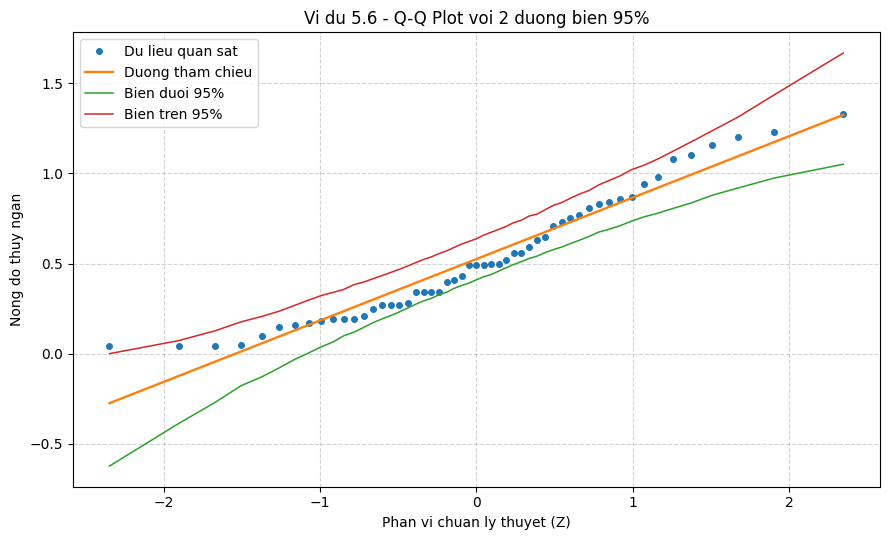

Hai duong bien la dai bao 95% theo tung phan vi cua Q-Q Plot,
KHONG phai khoang tin cay 95% cho ky vong da tinh o tren.


In [4]:
# 3. DỮ LIỆU KHÔNG CHUẨN, n > 30 - VÍ DỤ 5.6 (trang 109)
x = pd.read_excel('Data/Vi_du_5_6_n_lon_hon_30.xlsx', sheet_name='Du_lieu')['Gia_tri'].dropna().to_numpy(dtype=float)
n = len(x)
x_bar = np.mean(x)
s = np.std(x, ddof=1)                # Chưa biết phương sai tổng thể
alpha = 0.05

W, p_value = stats.shapiro(x)         # Kiểm định dữ liệu gốc có chuẩn không
z = stats.norm.ppf(1 - alpha / 2)    # <-- n > 30: TRA Z XẤP XỈ THEO GIÁO TRÌNH
sai_so = z * s / np.sqrt(n)          # Xấp xỉ theo định lý giới hạn trung tâm

print('VÍ DỤ 5.6 - KHÔNG CHUẨN, n > 30')
print(f'n = {n}, trung bình = {x_bar:.4f}, s = {s:.4f}')
print(f'Shapiro-Wilk: p = {p_value:.4f}')
print('Bác bỏ giả định phân phối chuẩn ở mức 5%' if p_value < alpha else 'Chưa bác bỏ giả định chuẩn ở mức 5%')
print(f'Khoảng tin cậy xấp xỉ 95%: [{x_bar-sai_so:.4f}; {x_bar+sai_so:.4f}] (đơn vị 10^-4 %)')
print('Sách trang 109 dùng x̄ = 0.52, s = 0.35 đã làm tròn: 0.43 < μ < 0.61')
print('Lưu ý: n > 30 không làm dữ liệu gốc trở thành phân phối chuẩn.')

# BIỂU ĐỒ XÁC SUẤT CHUẨN (Q-Q PLOT) - HÌNH 5.5
# Phân vị chuẩn lý thuyết và các quan sát được sắp xếp tăng dần
x_sorted = np.sort(x)
phan_vi = (np.arange(1, n + 1) - 0.5) / n
z_qq = stats.norm.ppf(phan_vi)

# Đường tham chiếu: hồi quy các quan sát theo phân vị chuẩn
he_so_goc, he_so_chan, _, _, _ = stats.linregress(z_qq, x_sorted)
duong_giua = he_so_chan + he_so_goc * z_qq

# 2 đường biên mô phỏng 95% (phân vị 2.5% và 97.5% ở mỗi vị trí)
B = 2000
rng = np.random.RandomState(42)  # Giữ kết quả biểu đồ không thay đổi giữa các lần chạy
mo_phong = rng.normal(loc=x_bar, scale=s, size=(B, n))
mo_phong_sap_xep = np.sort(mo_phong, axis=1)
bien_duoi = np.percentile(mo_phong_sap_xep, 2.5, axis=0)
bien_tren = np.percentile(mo_phong_sap_xep, 97.5, axis=0)

plt.figure(figsize=(9, 5.5))
plt.plot(z_qq, x_sorted, 'o', markersize=4, label='Du lieu quan sat')
plt.plot(z_qq, duong_giua, '-', linewidth=1.7, label='Duong tham chieu')
plt.plot(z_qq, bien_duoi, '-', linewidth=1.1, label='Bien duoi 95%')
plt.plot(z_qq, bien_tren, '-', linewidth=1.1, label='Bien tren 95%')
plt.title('Vi du 5.6 - Q-Q Plot voi 2 duong bien 95%')
plt.xlabel('Phan vi chuan ly thuyet (Z)')
plt.ylabel('Nong do thuy ngan')
plt.grid(True, linestyle='--', alpha=0.55)
plt.legend()
plt.tight_layout()
plt.show()

print('Hai duong bien la dai bao 95% theo tung phan vi cua Q-Q Plot,')
print('KHONG phai khoang tin cay 95% cho ky vong da tinh o tren.')
